# Proyecto final — Modelos y Simulación II

**Universidad de Antioquia · Facultad de Ingeniería**

- **Equipo:** Samuel Puerta Patiño, Simón Berrio Gaviria, Juan Estiven Carmona Muñoz
- **Grupo:** 5 · **Semestre:** 2026-2 · **Dataset:** *Financial Transactions & Fraud Detection* (Kaggle)

## Sección 4 (complemento): controles metodológicos y comparación de paradigmas

Este notebook **complementa** `03_modelos.ipynb`. No reemplaza sus resultados: responde a la retroalimentación del profesor y cierra puntos que el notebook 03 deja abiertos.

| Apartado | Pregunta que responde | Comentario del profesor |
|---|---|---|
| 1 | ¿Cuál es el máximo desempeño posible con la estructura de los datos? ¿Qué intervalos de confianza son válidos? | — |
| 2 | ¿Ponderación o SMOTE? ¿Submuestreo por árbol o ponderación en Random Forest? | 1 y 2 |
| 3 | ¿Ayuda un indicador de umbral sobre `risk_score` aprendido dentro de cada partición? | — |
| 4 | ¿Cómo se compara la clasificación binaria con la detección de anomalías y con la clasificación de una clase? ¿Ayuda un puntaje de anomalía como variable? | 3 y 4 |
| 5 | ¿Tiene señal el historial de `risk_score` del usuario? ¿Qué tamaño de efecto era detectable? | 3 |
| 6 | ¿Cambia algo con una partición temporal? | Promesa de la entrega 1 |
| 7 | ¿Dónde falla el modelo? | — |
| 8 | Conclusiones | — |

**Diseño común.** Todas las comparaciones usan las **mismas particiones externas** del notebook 03 (validación cruzada estratificada de 5 particiones con 2 repeticiones, semilla `RANDOM_STATE + 1`) y los mismos hiperparámetros fijos para cada modelo, de modo que las diferencias se deben a la estrategia y no al ajuste. Los hiperparámetros son los que el notebook 03 seleccionó (conclusión 5) cuando están reportados; para el Random Forest se usa una configuración razonable fija, porque aquí se compara entre estrategias y no se busca el óptimo.

> **Ejecución.** Requiere `data/caracteristicas.csv` (lo genera el notebook 01). Ejecutar desde la carpeta `notebooks/`.

In [1]:
from pathlib import Path
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats
from imblearn.ensemble import BalancedRandomForestClassifier
from imblearn.over_sampling import SMOTENC
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier, IsolationForest, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.model_selection import RepeatedStratifiedKFold, StratifiedKFold, cross_val_predict
from sklearn.neighbors import LocalOutlierFactor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import OneClassSVM, SVC
from sklearn.tree import DecisionTreeClassifier

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
N_PART, N_REP = 5, 2      # partición de la validación cruzada externa (igual que el notebook 03)
N_ARBOLES = 200
REPLICAS_BOOTSTRAP = 2000

DATA_PATH = Path("../data/caracteristicas.csv")
FIG_DIR = Path("../report/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)
COLORES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#8a5cd0"]
COLOR_REF = "#52514e"


def savefig(name):
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"{name}.pdf", bbox_inches="tight")
    plt.savefig(FIG_DIR / f"{name}.png", dpi=200, bbox_inches="tight")

In [2]:
# Se ordena por fecha: la validación temporal (apartado 6) y las variables de historial (apartado 5) lo requieren.
df = pd.read_csv(DATA_PATH, parse_dates=["timestamp"]).sort_values("timestamp").reset_index(drop=True)
df["is_weekend"] = df["is_weekend"].astype(float)
y = df["is_fraud"].to_numpy()

NUM_A = ["amount_log", "hour_sin", "hour_cos", "is_weekend"]
CAT = ["account_type", "category", "payment_method", "device_type"]
NUM_C = NUM_A + ["risk_score"]
FEATS_A = NUM_A + CAT          # A. Originales (sin risk_score)
FEATS_C = NUM_C + CAT          # C. Originales + risk_score
CAT_IDX = [FEATS_C.index(c) for c in CAT]

FRACCION_ALERTAS = 0.02


def _top(y_true, s):
    k = int(np.ceil(FRACCION_ALERTAS * len(y_true)))
    return np.asarray(y_true)[np.argsort(-np.asarray(s), kind="stable")[:k]]


def recall_top(y_true, s):
    return _top(y_true, s).sum() / np.sum(y_true)


def precision_top(y_true, s):
    return _top(y_true, s).mean()


FUNCIONES = {"pr_auc": average_precision_score, "roc_auc": roc_auc_score,
             "recall_2pct": recall_top, "precision_2pct": precision_top}


def metricas(y_true, s):
    return {m: f(y_true, s) for m, f in FUNCIONES.items()}


CV = RepeatedStratifiedKFold(n_splits=N_PART, n_repeats=N_REP, random_state=RANDOM_STATE + 1)
PARTICIONES = list(CV.split(df, y))
K = len(PARTICIONES)
R_NB = 1 / (N_PART - 1)       # cociente n_prueba / n_entrenamiento de la validación cruzada

print(f"Transacciones: {len(df):,} | fraudes: {y.sum()} ({100 * y.mean():.2f} %) | evaluaciones por modelo: {K}")

Transacciones: 10,000 | fraudes: 126 (1.26 %) | evaluaciones por modelo: 10


In [3]:
def ic_t(v, conf=0.95):
    """Intervalo t clásico sobre las evaluaciones de la validación cruzada (subestima la varianza)."""
    v = np.asarray(v, dtype=float)
    m = v.mean()
    h = stats.t.ppf((1 + conf) / 2, len(v) - 1) * v.std(ddof=1) / np.sqrt(len(v))
    return m, m - h, m + h


def ic_nb(v, r=R_NB, conf=0.95):
    """Intervalo con la corrección de Nadeau y Bengio (2003): las particiones comparten datos,
    así que la varianza de la media es s^2 (1/k + n_prueba/n_entrenamiento), no s^2 / k."""
    v = np.asarray(v, dtype=float)
    k = len(v)
    h = stats.t.ppf((1 + conf) / 2, k - 1) * np.sqrt(v.var(ddof=1) * (1 / k + r))
    return v.mean(), v.mean() - h, v.mean() + h


def fmt_nb(v):
    m, lo, hi = ic_nb(v)
    return f"{m:.3f} [{lo:.3f}, {hi:.3f}]"


def prueba_pareada_nb(a, b, r=R_NB):
    """Diferencia media a - b por partición y p-valor de la prueba t corregida."""
    d = np.asarray(a, dtype=float) - np.asarray(b, dtype=float)
    k = len(d)
    var = d.var(ddof=1) * (1 / k + r)
    if var <= 0:
        return d.mean(), np.nan
    t = d.mean() / np.sqrt(var)
    return d.mean(), 2 * stats.t.sf(abs(t), k - 1)


print(f"Factor de inflación de la varianza respecto al IC t clásico: {(1 / K + R_NB) / (1 / K):.2f} "
      f"(los intervalos se ensanchan {np.sqrt((1 / K + R_NB) / (1 / K)):.2f} veces)")

Factor de inflación de la varianza respecto al IC t clásico: 3.50 (los intervalos se ensanchan 1.87 veces)


## 1. Techo de desempeño e intervalos de confianza

### 1.1 ¿Cuánto es lo máximo que se puede lograr?

La sección 2 mostró que la única señal es un grupo de transacciones con `risk_score` ≥ 70: contiene una cuarta parte de los fraudes, y dentro de ese grupo `risk_score` ya no distingue fraudes de normales. Si eso es cierto, **la mejor regla posible es marcar ese grupo** y cualquier modelo está limitado por ella.

Para cuantificar el límite se simula la regla ideal: en particiones del tamaño de una partición de prueba, cada transacción pertenece al grupo alto con la probabilidad observada para su clase, y se ordena marcando primero ese grupo (con desempate aleatorio dentro de cada grupo). El umbral 70 se vio en el análisis exploratorio con todos los datos; por eso este techo es **descriptivo** (resume la estructura observada) y no una estimación de generalización.

In [4]:
UMBRAL = 70
alto = (df["risk_score"] >= UMBRAL).to_numpy()
p_alto_fraude, p_alto_normal = alto[y == 1].mean(), alto[y == 0].mean()
print(f"P(risk_score ≥ {UMBRAL} | fraude) = {p_alto_fraude:.3f} · P(risk_score ≥ {UMBRAL} | normal) = {p_alto_normal:.4f} · "
      f"P(fraude | risk_score ≥ {UMBRAL}) = {y[alto].mean():.3f}")


def techo(N, repeticiones=2000, tasa=y.mean(), semilla=RANDOM_STATE):
    rng = np.random.default_rng(semilla)
    ap, rec = [], []
    for _ in range(repeticiones):
        yy = (rng.random(N) < tasa).astype(int)
        if yy.sum() == 0:
            continue
        h = np.where(yy == 1, rng.random(N) < p_alto_fraude, rng.random(N) < p_alto_normal)
        s = h + rng.random(N) * 0.5
        ap.append(average_precision_score(yy, s))
        rec.append(recall_top(yy, s))
    return np.array(ap), np.array(rec)


ap_techo, rec_techo = techo(len(df) // N_PART)
ref_rs = pd.DataFrame([metricas(y[te], df["risk_score"].to_numpy()[te]) for _, te in PARTICIONES])

resumen_techo = pd.DataFrame({
    "PR-AUC": [f"{ap_techo.mean():.3f} (p5–p95: {np.percentile(ap_techo, 5):.3f}–{np.percentile(ap_techo, 95):.3f})",
               fmt_nb(ref_rs["pr_auc"]), f"{y.mean():.3f}"],
    "Recall@2 %": [f"{rec_techo.mean():.3f}", fmt_nb(ref_rs["recall_2pct"]), f"{FRACCION_ALERTAS:.3f}"],
}, index=["Regla ideal (techo, simulada)", "risk_score sin modelo (mismas particiones)", "Clasificador aleatorio"])
resumen_techo

P(risk_score ≥ 70 | fraude) = 0.238 · P(risk_score ≥ 70 | normal) = 0.0067 · P(fraude | risk_score ≥ 70) = 0.312


,PR-AUC,Recall@2 %
"Regla ideal (techo, simulada)",0.122 (p5–p95: 0.037–0.234),0.246
risk_score sin modelo (mismas particiones),"0.121 [0.045, 0.197]","0.238 [0.112, 0.365]"
Clasificador aleatorio,0.013,0.020


### 1.2 Intervalos de confianza válidos

El intervalo t del notebook 03 trata las evaluaciones de la validación cruzada como independientes, pero cada par de particiones comparte la mayor parte de los datos de entrenamiento, así que **subestima la varianza**. La corrección de Nadeau y Bengio (2003) la multiplica por $(1/k + n_{\text{prueba}}/n_{\text{entrenamiento}})\,k$. Con 5 particiones, eso ensancha los intervalos aproximadamente 1,9 veces. Desde aquí, todos los intervalos de este notebook usan esa corrección, y las diferencias entre estrategias se contrastan con una prueba t pareada con la misma corrección.

> Nota de nomenclatura. Lo que el notebook 03 llama "5×2" es una validación cruzada de **5 particiones repetida 2 veces**; el "5×2cv" de Dietterich son 5 repeticiones de 2 particiones. Para evitar confusiones, en el informe se debe escribir la descripción completa.

## 2. Desbalance: ponderación, submuestreo por árbol y SMOTE (comentarios 1 y 2)

El profesor recomendó **probar la ponderación de clases** (SMOTE "puede que no nos funcione bien") y un **Random Forest con submuestreo**: varios árboles, cada uno con todos los fraudes y un subgrupo de normales de tamaño similar. Ambas estrategias están en el notebook 03. Aquí se les agregan **controles** para que la elección tenga evidencia propia y no solo una recomendación:

| Modelo | Estrategias comparadas |
|---|---|
| Regresión logística y gradient boosting | Sin tratamiento · **Ponderación de clases (principal)** · SMOTENC |
| Random Forest | Sin tratamiento · Ponderación (`balanced_subsample`) · **Submuestreo por árbol (RF balanceado, principal)** · SMOTENC |

SMOTENC (la variante de SMOTE para variables mixtas) se aplica solo al conjunto de entrenamiento de cada partición, con una proporción fraude/normal de 0,5, y se incluye porque la entrega 1 prometió compararlo. Se usa el conjunto C (variables originales + `risk_score`), el único donde hay señal que preservar.

In [5]:
def prep(num, cat=CAT):
    pasos = [("n", StandardScaler(), num)]
    if cat:
        pasos.append(("c", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat))
    return ColumnTransformer(pasos)


def puntaje(modelo, X):
    final = modelo[-1]
    return modelo.decision_function(X) if hasattr(final, "decision_function") else modelo.predict_proba(X)[:, 1]


def evaluar(fabrica, cols, extra=None):
    """Ajusta el modelo en cada partición externa y evalúa en la partición de prueba."""
    filas = []
    for i, (tr, te) in enumerate(PARTICIONES):
        m = fabrica()
        m.fit(df.iloc[tr][cols], y[tr])
        fila = {"particion": i, **metricas(y[te], puntaje(m, df.iloc[te][cols]))}
        if extra is not None:
            fila.update(extra(m))
        filas.append(fila)
    return pd.DataFrame(filas)


def est_lr(cw):
    return LogisticRegression(C=0.001, class_weight=cw, max_iter=5000)


def est_gb(cw):
    return HistGradientBoostingClassifier(max_iter=200, max_depth=2, learning_rate=0.03, class_weight=cw,
                                          early_stopping=False, random_state=RANDOM_STATE)


def est_rf(cw):
    return RandomForestClassifier(n_estimators=N_ARBOLES, min_samples_leaf=20, class_weight=cw, n_jobs=1,
                                  random_state=RANDOM_STATE)


def est_brf():
    return BalancedRandomForestClassifier(n_estimators=N_ARBOLES, min_samples_leaf=20, sampling_strategy="all",
                                          replacement=True, bootstrap=False, n_jobs=1, random_state=RANDOM_STATE)


def pipe(est, num=NUM_C):
    return Pipeline([("pre", prep(num)), ("modelo", est)])


def pipe_smote(est):
    return ImbPipeline([("sm", SMOTENC(categorical_features=CAT_IDX, sampling_strategy=0.5, random_state=RANDOM_STATE)),
                        ("pre", prep(NUM_C)), ("modelo", est)])


ESTRATEGIAS = {
    "Regresión logística": {
        "Sin tratamiento": lambda: pipe(est_lr(None)),
        "Ponderación de clases": lambda: pipe(est_lr("balanced")),
        "SMOTENC": lambda: pipe_smote(est_lr(None)),
    },
    "Gradient boosting": {
        "Sin tratamiento": lambda: pipe(est_gb(None)),
        "Ponderación de clases": lambda: pipe(est_gb("balanced")),
        "SMOTENC": lambda: pipe_smote(est_gb(None)),
    },
    "Random Forest": {
        "Sin tratamiento": lambda: pipe(est_rf(None)),
        "Ponderación (balanced_subsample)": lambda: pipe(est_rf("balanced_subsample")),
        "Submuestreo por árbol (RF balanceado)": lambda: pipe(est_brf()),
        "SMOTENC": lambda: pipe_smote(est_rf(None)),
    },
}
PRINCIPAL = {"Regresión logística": "Ponderación de clases", "Gradient boosting": "Ponderación de clases",
             "Random Forest": "Submuestreo por árbol (RF balanceado)"}

res_desb = {}
inicio = time.time()
for modelo, estrategias in ESTRATEGIAS.items():
    for estrategia, fabrica in estrategias.items():
        res_desb[(modelo, estrategia)] = evaluar(fabrica, FEATS_C)
    print(f"{modelo}: listo ({time.time() - inicio:.0f} s acumulados)")

Regresión logística: listo (2 s acumulados)


Gradient boosting: listo (11 s acumulados)


Random Forest: listo (42 s acumulados)


In [6]:
filas = []
for (modelo, estrategia), r in res_desb.items():
    base = res_desb[(modelo, PRINCIPAL[modelo])]["pr_auc"]
    dif, p = prueba_pareada_nb(r["pr_auc"], base)
    filas.append({"modelo": modelo, "estrategia": estrategia + (" (principal)" if estrategia == PRINCIPAL[modelo] else ""),
                  "PR-AUC [IC 95 %, Nadeau–Bengio]": fmt_nb(r["pr_auc"]), "ROC-AUC": r["roc_auc"].mean(),
                  "Recall@2 %": r["recall_2pct"].mean(),
                  "Dif. PR-AUC vs principal": dif if estrategia != PRINCIPAL[modelo] else np.nan,
                  "p (t pareada corregida)": p if estrategia != PRINCIPAL[modelo] else np.nan})
tabla_desb = pd.DataFrame(filas).set_index(["modelo", "estrategia"])
tabla_desb

PR-AUC [IC 95 %, Nadeau–Bengio]  \
modelo              estrategia                                                                          
Regresión logística Sin tratamiento                                              0.085 [0.030, 0.140]   
                    Ponderación de clases (principal)                            0.065 [0.021, 0.110]   
                    SMOTENC                                                      0.036 [0.009, 0.063]   
Gradient boosting   Sin tratamiento                                              0.102 [0.030, 0.174]   
                    Ponderación de clases (principal)                            0.121 [0.038, 0.204]   
                    SMOTENC                                                      0.084 [0.031, 0.137]   
Random Forest       Sin tratamiento                                              0.107 [0.040, 0.173]   
                    Ponderación (balanced_subsample)                             0.101 [0.029, 0.172]   
                    Submuestreo por árbol (RF balanceado) (principal)            0.087 [0.026, 0.149]   
                    SMOTENC                                                      0.073 [0.026, 0.119]   

                                                                       ROC-AUC  \
modelo              estrategia                                                   
Regresión logística Sin tratamiento                                      0.597   
                    Ponderación de clases (principal)                    0.586   
                    SMOTENC                                              0.579   
Gradient boosting   Sin tratamiento                                      0.543   
                    Ponderación de clases (principal)                    0.552   
                    SMOTENC                                              0.581   
Random Forest       Sin tratamiento                                      0.600   
                    Ponderación (balanced_subsample)                     0.591   
                    Submuestreo por árbol (RF balanceado) (principal)    0.570   
                    SMOTENC                                              0.561   

                                                                       Recall@2 %  \
modelo              estrategia                                                      
Regresión logística Sin tratamiento                                         0.210   
                    Ponderación de clases (principal)                       0.171   
                    SMOTENC                                                 0.095   
Gradient boosting   Sin tratamiento                                         0.246   
                    Ponderación de clases (principal)                       0.242   
                    SMOTENC                                                 0.199   
Random Forest       Sin tratamiento                                         0.242   
                    Ponderación (balanced_subsample)                        0.234   
                    Submuestreo por árbol (RF balanceado) (principal)       0.234   
                    SMOTENC                                                 0.179   

                                                                       Dif. PR-AUC vs principal  \
modelo              estrategia                                                                    
Regresión logística Sin tratamiento                                                       0.020   
                    Ponderación de clases (principal)                                       NaN   
                    SMOTENC                                                              -0.029   
Gradient boosting   Sin tratamiento                                                      -0.019   
                    Ponderación de clases (principal)                                       NaN   
                    SMOTENC                                                              -0.037   
Random Fore

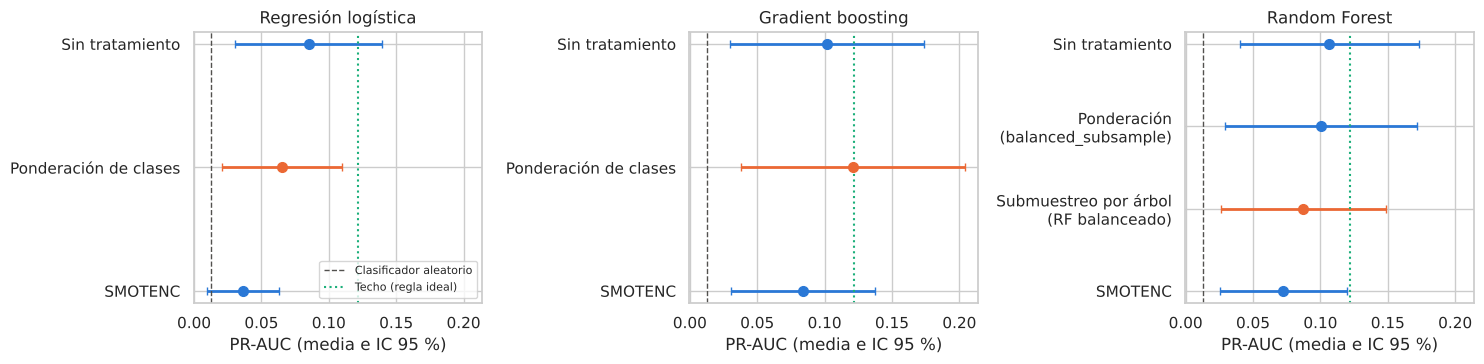

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), sharex=True)
techo_medio = ap_techo.mean()
for ax, (modelo, estrategias) in zip(axes, ESTRATEGIAS.items()):
    for j, estrategia in enumerate(estrategias):
        m, lo, hi = ic_nb(res_desb[(modelo, estrategia)]["pr_auc"])
        ax.errorbar(m, j, xerr=[[m - lo], [hi - m]], fmt="o", ms=7, lw=2, capsize=3,
                    color=COLORES[1] if estrategia == PRINCIPAL[modelo] else COLORES[0])
    ax.axvline(y.mean(), color=COLOR_REF, ls="--", lw=1, label="Clasificador aleatorio")
    ax.axvline(techo_medio, color=COLORES[2], ls=":", lw=1.5, label="Techo (regla ideal)")
    ax.set_yticks(range(len(estrategias)), [e.replace(" (", "\n(") for e in estrategias])
    ax.invert_yaxis()
    ax.set_title(modelo)
    ax.set_xlabel("PR-AUC (media e IC 95 %)")
axes[0].legend(fontsize=8, loc="lower right")
savefig("fig_desbalance_controles")
plt.show()

*Figura (controles de desbalance). PR-AUC por estrategia de manejo del desbalance (conjunto C), con intervalos de confianza al 95 % con la corrección de Nadeau y Bengio. En naranja, la estrategia principal de cada modelo; la línea discontinua es un clasificador aleatorio y la punteada, el techo de la regla ideal.*

## 3. Indicador de umbral sobre `risk_score` aprendido dentro de cada partición

`risk_score` entra a los modelos como una variable continua, pero la señal no es una pendiente: es un **escalón** en torno a 70. Los modelos de árboles lo aprenden solos; la regresión logística, la SVM y el KNN no. El análisis exploratorio fijó el umbral 70 mirando todos los datos, y usarlo como variable sería una fuga leve. Por eso aquí el umbral se **aprende dentro de cada partición de entrenamiento** con un árbol de decisión de profundidad 1 sobre `risk_score`, y se agrega como variable `risk_alto`.

El conjunto **E** es el conjunto C más `risk_alto`.

In [8]:
class IndicadorRiesgo(BaseEstimator, TransformerMixin):
    """Agrega `risk_alto` = risk_score > umbral, con el umbral aprendido (árbol de profundidad 1) en el conjunto de entrenamiento."""

    def __init__(self, columna="risk_score"):
        self.columna = columna

    def fit(self, X, y):
        arbol = DecisionTreeClassifier(max_depth=1, class_weight="balanced", random_state=RANDOM_STATE)
        arbol.fit(X[[self.columna]], y)
        self.umbral_ = float(arbol.tree_.threshold[0])
        return self

    def transform(self, X):
        X = X.copy()
        X["risk_alto"] = (X[self.columna] > self.umbral_).astype(float)
        return X


NUM_E = NUM_C + ["risk_alto"]


def pipe_E(est):
    return Pipeline([("ind", IndicadorRiesgo()), ("pre", prep(NUM_E)), ("modelo", est)])


def est_svm():
    return SVC(kernel="rbf", C=0.1, gamma=0.01, class_weight="balanced")


MODELOS_E = {"Regresión logística": lambda: est_lr("balanced"), "SVM (RBF)": est_svm,
             "Gradient boosting": lambda: est_gb("balanced")}
res_E, umbrales = {}, {}
inicio = time.time()
for nombre, est in MODELOS_E.items():
    res_E[(nombre, "C")] = evaluar(lambda: pipe(est()), FEATS_C)
    res_E[(nombre, "E")] = evaluar(lambda: pipe_E(est()), FEATS_C,
                                   extra=lambda m: {"umbral": m.named_steps["ind"].umbral_})
    print(f"{nombre}: listo ({time.time() - inicio:.0f} s acumulados)")

filas = []
for nombre in MODELOS_E:
    c, e = res_E[(nombre, "C")], res_E[(nombre, "E")]
    dif, p = prueba_pareada_nb(e["pr_auc"], c["pr_auc"])
    filas.append({"modelo": nombre, "C: PR-AUC [IC 95 %]": fmt_nb(c["pr_auc"]), "E: PR-AUC [IC 95 %]": fmt_nb(e["pr_auc"]),
                  "Aporte de risk_alto (E − C)": dif, "p (t pareada corregida)": p,
                  "Recall@2 % (C → E)": f"{c['recall_2pct'].mean():.3f} → {e['recall_2pct'].mean():.3f}"})
tabla_E = pd.DataFrame(filas).set_index("modelo")
umb = res_E[("Gradient boosting", "E")]["umbral"]
print(f"Umbral aprendido en las {K} particiones de entrenamiento: mediana {umb.median():.1f} (mín. {umb.min():.1f}, máx. {umb.max():.1f})")
tabla_E

Regresión logística: listo (1 s acumulados)


SVM (RBF): listo (48 s acumulados)


Gradient boosting: listo (53 s acumulados)
Umbral aprendido en las 10 particiones de entrenamiento: mediana 69.9 (mín. 69.9, máx. 70.6)


,C: PR-AUC [IC 95 %],E: PR-AUC [IC 95 %],Aporte de risk_alto (E − C),p (t pareada corregida),Recall@2 % (C → E)
modelo,,,,,
Regresión logística,"0.065 [0.021, 0.110]","0.103 [0.034, 0.171]",0.037,0.094,0.171 → 0.238
SVM (RBF),"0.080 [0.029, 0.131]","0.108 [0.031, 0.186]",0.028,0.382,0.166 → 0.234
Gradient boosting,"0.121 [0.038, 0.204]","0.116 [0.031, 0.200]",-0.005,0.463,0.242 → 0.234


## 4. Clasificación binaria frente a detección de anomalías y de una clase (comentarios 3 y 4)

El profesor sugirió comparar la clasificación binaria con aproximaciones de **detección de anomalías / clasificación de una clase**. La entrega 1 había descartado la detección de anomalías por argumentos cualitativos; aquí se somete a prueba con las mismas particiones y métricas.

**Enfoque.** Detección de novedad: cada modelo se ajusta **solo con las transacciones normales** del conjunto de entrenamiento y puntúa cada transacción de prueba según qué tan atípica es. No usa etiquetas de fraude para ajustarse, que es la ventaja práctica del enfoque.

| Modelo de una clase | Configuraciones (sensibilidad) |
|---|---|
| Isolation Forest | 200 árboles |
| Local Outlier Factor (novedad) | `n_neighbors` = 20, 50 |
| One-Class SVM (RBF) | `nu` = 0,01; 0,05 (ajustado con una submuestra de 3.000 normales por costo) |
| Distancia de Mahalanobis (modelo gaussiano) | — |

Se evalúan sobre tres espacios: **A** (sin `risk_score`), **C** (con `risk_score`) y **solo `risk_score`**, que aísla qué ocurre con la única variable informativa. Las configuraciones se reportan **todas**, sin elegir la mejor sobre las mismas particiones, porque eso sesgaría el resultado a favor de los métodos con más configuraciones.

Como referencia supervisada se usa el gradient boosting ponderado, y como segundo experimento se prueba el enfoque de Carcillo et al. (2021): el puntaje de anomalía no supervisado como **variable de entrada** de un clasificador supervisado.

In [9]:
ESPACIOS_UC = {"A: sin risk_score": (NUM_A, CAT), "C: con risk_score": (NUM_C, CAT), "Solo risk_score": (["risk_score"], [])}


def puntajes_una_clase(tr, te, num, cat, semilla):
    cols = num + cat
    pre = prep(num, cat).fit(df.iloc[tr][cols][y[tr] == 0])
    Zn = pre.transform(df.iloc[tr][cols][y[tr] == 0])
    Zt = pre.transform(df.iloc[te][cols])
    salida = {}
    salida["Isolation Forest"] = -IsolationForest(n_estimators=200, random_state=RANDOM_STATE).fit(Zn).score_samples(Zt)
    for k in (20, 50):
        salida[f"LOF (k = {k})"] = -LocalOutlierFactor(n_neighbors=k, novelty=True).fit(Zn).score_samples(Zt)
    sub = np.random.default_rng(semilla).choice(len(Zn), min(3000, len(Zn)), replace=False)
    for nu in (0.01, 0.05):
        salida[f"One-Class SVM (nu = {nu})"] = -OneClassSVM(nu=nu, gamma="scale").fit(Zn[sub]).score_samples(Zt)
    cov = np.atleast_2d(np.cov(Zn.T)) + 1e-3 * np.eye(Zn.shape[1])
    d = Zt - Zn.mean(0)
    salida["Mahalanobis (gaussiana)"] = np.einsum("ij,jk,ik->i", d, np.linalg.inv(cov), d)
    return salida


filas = []
inicio = time.time()
for i, (tr, te) in enumerate(PARTICIONES):
    for espacio, (num, cat) in ESPACIOS_UC.items():
        for modelo, s in puntajes_una_clase(tr, te, num, cat, i).items():
            filas.append({"particion": i, "espacio": espacio, "modelo": modelo, **metricas(y[te], s)})
    print(f"partición {i + 1}/{K} ({time.time() - inicio:.0f} s)", end="\r")
res_uc = pd.DataFrame(filas)

# Referencias supervisadas en los mismos espacios
ref_gb_A = evaluar(lambda: pipe(est_gb("balanced"), NUM_A), FEATS_A)
ref_gb_C = res_desb[("Gradient boosting", "Ponderación de clases")]
ref_rs_alone = pd.DataFrame([metricas(y[te], df["risk_score"].to_numpy()[te]) for _, te in PARTICIONES])

In [10]:
def celda(espacio, modelo, m="pr_auc"):
    v = res_uc[(res_uc["espacio"] == espacio) & (res_uc["modelo"] == modelo)][m]
    return v.mean()


modelos_uc = list(res_uc["modelo"].unique())
tabla_uc = pd.DataFrame({esp: [celda(esp, m) for m in modelos_uc] for esp in ESPACIOS_UC}, index=modelos_uc)
tabla_uc.loc["— Gradient boosting ponderado (supervisado)"] = [ref_gb_A["pr_auc"].mean(), ref_gb_C["pr_auc"].mean(), np.nan]
tabla_uc.loc["— risk_score sin modelo"] = [np.nan, np.nan, ref_rs_alone["pr_auc"].mean()]
tabla_uc.loc["— Clasificador aleatorio"] = [y.mean()] * 3
tabla_uc.loc["— Techo (regla ideal)"] = [np.nan, np.nan, ap_techo.mean()]
print("PR-AUC media sobre las particiones externas")
display(tabla_uc)

roc_A = res_uc[res_uc["espacio"] == "A: sin risk_score"].groupby("modelo")["roc_auc"].mean()
print(f"\nROC-AUC en el espacio A (sin risk_score): de {roc_A.min():.3f} a {roc_A.max():.3f} entre los modelos de una clase")

PR-AUC media sobre las particiones externas


,A: sin risk_score,C: con risk_score,Solo risk_score
Isolation Forest,0.017,0.031,0.119
LOF (k = 20),0.015,0.052,0.056
LOF (k = 50),0.017,0.062,0.092
One-Class SVM (nu = 0.01),0.016,0.057,0.048
One-Class SVM (nu = 0.05),0.017,0.066,0.121
Mahalanobis (gaussiana),0.015,0.029,0.121
— Gradient boosting ponderado (supervisado),0.013,0.121,NaN
— risk_score sin modelo,NaN,NaN,0.121
— Clasificador aleatorio,0.013,0.013,0.013
— Techo (regla ideal),NaN,NaN,0.122



ROC-AUC en el espacio A (sin risk_score): de 0.470 a 0.499 entre los modelos de una clase


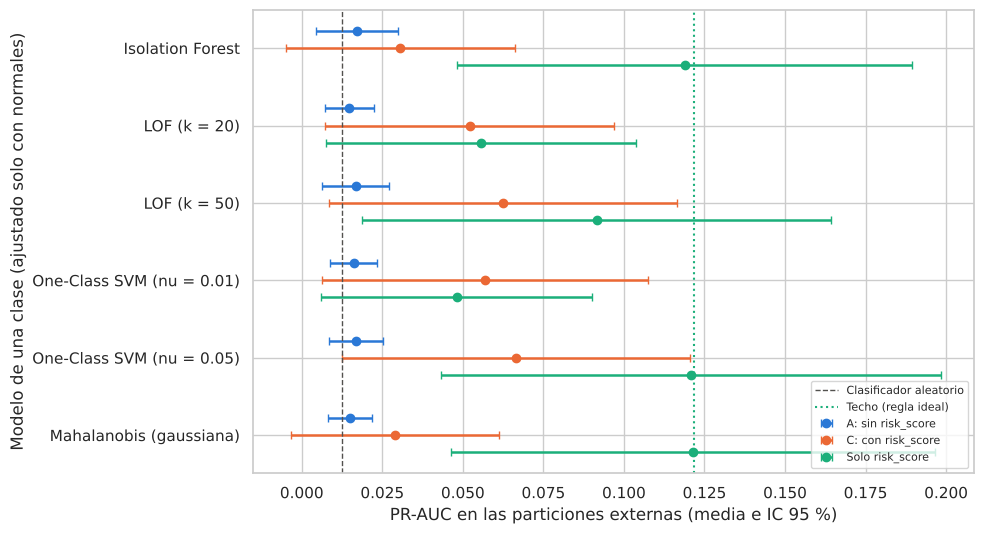

In [11]:
fig, ax = plt.subplots(figsize=(10, 5.5))
orden = modelos_uc
for j, (espacio, color) in enumerate(zip(ESPACIOS_UC, COLORES)):
    t = res_uc[res_uc["espacio"] == espacio].groupby("modelo")["pr_auc"].apply(lambda v: ic_nb(v)).loc[orden]
    medias = [x[0] for x in t]
    err = [[x[0] - x[1] for x in t], [x[2] - x[0] for x in t]]
    ax.errorbar(medias, np.arange(len(orden)) + (j - 1) * 0.22, xerr=err, fmt="o", ms=6, lw=1.8, capsize=3,
                color=color, label=espacio)
ax.axvline(y.mean(), color=COLOR_REF, ls="--", lw=1, label="Clasificador aleatorio")
ax.axvline(ap_techo.mean(), color=COLORES[2], ls=":", lw=1.5, label="Techo (regla ideal)")
ax.set_yticks(range(len(orden)), orden)
ax.invert_yaxis()
ax.set_xlabel("PR-AUC en las particiones externas (media e IC 95 %)")
ax.set_ylabel("Modelo de una clase (ajustado solo con normales)")
ax.legend(fontsize=8, loc="lower right")
savefig("fig_paradigmas")
plt.show()

*Figura (paradigmas). PR-AUC de los modelos de una clase en tres espacios de variables (intervalos de confianza al 95 % con corrección de Nadeau y Bengio). Sin `risk_score` ninguno supera al clasificador aleatorio; solo cuando se aplican a `risk_score` solo se acercan al techo.*

### Puntaje de anomalía como variable de entrada (Carcillo et al., 2021)

Se ajusta un Isolation Forest con las transacciones normales de cada partición de entrenamiento y su puntaje se agrega como variable de un gradient boosting ponderado, que se compara con el mismo modelo sin el puntaje.

In [12]:
def matriz_gb(idx, num, anomalia=None, columnas=None):
    X = df.iloc[idx][num + CAT].copy()
    if anomalia is not None:
        X["anom_if"] = anomalia
    X = pd.get_dummies(X, columns=CAT).astype(float)
    return X if columnas is None else X.reindex(columns=columnas, fill_value=0.0)


filas = []
for i, (tr, te) in enumerate(PARTICIONES):
    pre = prep(NUM_A).fit(df.iloc[tr][FEATS_A][y[tr] == 0])
    bosque = IsolationForest(n_estimators=200, random_state=RANDOM_STATE).fit(pre.transform(df.iloc[tr][FEATS_A][y[tr] == 0]))
    a_tr = -bosque.score_samples(pre.transform(df.iloc[tr][FEATS_A]))
    a_te = -bosque.score_samples(pre.transform(df.iloc[te][FEATS_A]))
    for etiqueta, num in (("A", NUM_A), ("C", NUM_C)):
        for con in (False, True):
            Xa = matriz_gb(tr, num, a_tr if con else None)
            Xb = matriz_gb(te, num, a_te if con else None, Xa.columns)
            gb = est_gb("balanced").fit(Xa, y[tr])
            filas.append({"particion": i, "espacio": etiqueta, "con_anomalia": con,
                          **metricas(y[te], gb.predict_proba(Xb)[:, 1])})
res_anom = pd.DataFrame(filas)

out = []
for etiqueta in ("A", "C"):
    base = res_anom[(res_anom["espacio"] == etiqueta) & (~res_anom["con_anomalia"])]["pr_auc"].to_numpy()
    con = res_anom[(res_anom["espacio"] == etiqueta) & (res_anom["con_anomalia"])]["pr_auc"].to_numpy()
    dif, p = prueba_pareada_nb(con, base)
    out.append({"espacio": etiqueta, "GB sin puntaje": fmt_nb(base), "GB con puntaje de anomalía": fmt_nb(con),
                "Diferencia": dif, "p (t pareada corregida)": p})
pd.DataFrame(out).set_index("espacio")

,GB sin puntaje,GB con puntaje de anomalía,Diferencia,p (t pareada corregida)
espacio,,,,
A,"0.013 [0.009, 0.018]","0.015 [0.005, 0.025]",0.002,0.615
C,"0.114 [0.027, 0.201]","0.112 [0.034, 0.191]",-0.002,0.900


## 5. Historial de `risk_score` del usuario (comentario 3)

El notebook 01 evaluó variables de historial construidas con las características de cada transacción (categoría, dispositivo, medio de pago, horario, monto). Falta un historial que usa la **única variable informativa**: ¿los usuarios con transacciones previas de `risk_score` alto tienen más probabilidad de fraude? Se calculan, **solo con transacciones anteriores del mismo usuario**, la media y el máximo previos de `risk_score` y el número de transacciones previas con `risk_score` ≥ 70. La diferencia entre `risk_score` y su media previa se incluye como contraste: por construcción contiene a `risk_score` y no es evidencia de señal nueva.

También se calcula qué tan grande tenía que ser un efecto para ser detectable con 126 fraudes (potencia 0,8, α = 0,05, aproximación normal bajo la hipótesis nula con error estándar de Hanley y McNeil).

In [13]:
g = df.groupby("user_id")["risk_score"]
df["prev_n"] = df.groupby("user_id").cumcount()
df["prev_risk_media"] = g.transform(lambda s: s.shift(1).expanding().mean())
df["prev_risk_max"] = g.transform(lambda s: s.shift(1).expanding().max())
df["prev_n_alto"] = g.transform(lambda s: (s.shift(1) >= UMBRAL).astype(float).expanding().sum())
df["risk_menos_prev"] = df["risk_score"] - df["prev_risk_media"]

h = df[df["prev_n"] >= 1].copy()
yh = h["is_fraud"].to_numpy()


def auc_con_ic(yv, x, replicas=1000, semilla=RANDOM_STATE):
    rng = np.random.default_rng(semilla)
    pos, neg = np.flatnonzero(yv == 1), np.flatnonzero(yv == 0)
    v = [roc_auc_score(yv[idx], x[idx]) for idx in
         (np.concatenate([rng.choice(pos, len(pos)), rng.choice(neg, len(neg))]) for _ in range(replicas))]
    return roc_auc_score(yv, x), np.percentile(v, 2.5), np.percentile(v, 97.5)


filas = []
for col, nota in [("prev_risk_media", ""), ("prev_risk_max", ""), ("prev_n_alto", ""),
                  ("risk_menos_prev", "contiene a risk_score: no es señal nueva"),
                  ("risk_score", "referencia (misma submuestra)")]:
    a, lo, hi = auc_con_ic(yh, h[col].to_numpy())
    filas.append({"variable": col, "AUC univariada": a, "IC 95 % (bootstrap)": f"[{lo:.3f}, {hi:.3f}]", "nota": nota})
print(f"Transacciones con al menos una previa del usuario: {len(h):,} ({yh.sum()} fraudes)")
display(pd.DataFrame(filas).set_index("variable"))


def auc_minima_detectable(n1, n0, alfa=0.05, potencia=0.8):
    se0 = np.sqrt((n1 + n0 + 1) / (12 * n1 * n0))
    return 0.5 + (stats.norm.ppf(1 - alfa / 2) + stats.norm.ppf(potencia)) * se0


print(f"AUC mínima detectable con todos los datos (126 fraudes): ≈ {auc_minima_detectable(y.sum(), (y == 0).sum()):.3f}")
print(f"AUC mínima detectable con la submuestra con historial ({yh.sum()} fraudes): ≈ {auc_minima_detectable(yh.sum(), (yh == 0).sum()):.3f}")

Transacciones con al menos una previa del usuario: 7,858 (103 fraudes)


,AUC univariada,IC 95 % (bootstrap),nota
variable,,,
prev_risk_media,0.488,"[0.427, 0.549]",
prev_risk_max,0.487,"[0.429, 0.541]",
prev_n_alto,0.496,"[0.485, 0.511]",
risk_menos_prev,0.606,"[0.543, 0.671]",contiene a risk_score: no es señal nueva
risk_score,0.615,"[0.553, 0.677]",referencia (misma submuestra)


AUC mínima detectable con todos los datos (126 fraudes): ≈ 0.573
AUC mínima detectable con la submuestra con historial (103 fraudes): ≈ 0.580


## 6. Validación temporal de control

La entrega 1 prometió una partición temporal porque los trabajos revisados validan respetando el tiempo. El notebook 03 usa una partición aleatoria con el argumento de que los fraudes llegan sin tendencia ni rachas. Este apartado lo **comprueba**: se entrena con el 80 % más antiguo y se prueba con el 20 % más reciente, con los mismos hiperparámetros fijos. No reemplaza la validación cruzada (la prueba temporal tiene pocos fraudes); sirve para descartar una deriva.

In [14]:
corte = int(0.8 * len(df))
tr_t, te_t = np.arange(corte), np.arange(corte, len(df))
print(f"Entrenamiento: {len(tr_t):,} transacciones, {y[tr_t].sum()} fraudes (hasta {df['timestamp'].iloc[corte - 1]:%Y-%m-%d}) · "
      f"Prueba: {len(te_t):,} transacciones, {y[te_t].sum()} fraudes (desde {df['timestamp'].iloc[corte]:%Y-%m-%d})")


def bootstrap_ic(y_true, s, funcion, replicas=REPLICAS_BOOTSTRAP, semilla=RANDOM_STATE):
    rng = np.random.default_rng(semilla)
    pos, neg = np.flatnonzero(y_true == 1), np.flatnonzero(y_true == 0)
    v = [funcion(y_true[i], s[i]) for i in
         (np.concatenate([rng.choice(pos, len(pos)), rng.choice(neg, len(neg))]) for _ in range(replicas))]
    return np.percentile(v, [2.5, 97.5])


CONFIG_T = {
    "Regresión logística ponderada": lambda num: pipe(est_lr("balanced"), num),
    "Gradient boosting ponderado": lambda num: pipe(est_gb("balanced"), num),
    "Random Forest balanceado": lambda num: pipe(est_brf(), num),
}
filas = []
for espacio, (cols, num) in {"A: sin risk_score": (FEATS_A, NUM_A), "C: con risk_score": (FEATS_C, NUM_C)}.items():
    for nombre, fabrica in CONFIG_T.items():
        m = fabrica(num).fit(df.iloc[tr_t][cols], y[tr_t])
        s = puntaje(m, df.iloc[te_t][cols])
        lo, hi = bootstrap_ic(y[te_t], s, average_precision_score)
        filas.append({"espacio": espacio, "modelo": nombre, "PR-AUC": average_precision_score(y[te_t], s),
                      "IC 95 % (bootstrap)": f"[{lo:.3f}, {hi:.3f}]", "ROC-AUC": roc_auc_score(y[te_t], s),
                      "Recall@2 %": recall_top(y[te_t], s)})
s_rs = df["risk_score"].to_numpy()[te_t]
lo, hi = bootstrap_ic(y[te_t], s_rs, average_precision_score)
filas.append({"espacio": "—", "modelo": "risk_score sin modelo", "PR-AUC": average_precision_score(y[te_t], s_rs),
              "IC 95 % (bootstrap)": f"[{lo:.3f}, {hi:.3f}]", "ROC-AUC": roc_auc_score(y[te_t], s_rs),
              "Recall@2 %": recall_top(y[te_t], s_rs)})
tabla_temporal = pd.DataFrame(filas).set_index(["espacio", "modelo"])
print(f"Referencia: clasificador aleatorio PR-AUC = {y[te_t].mean():.4f}")
tabla_temporal

Entrenamiento: 8,000 transacciones, 102 fraudes (hasta 2026-06-14) · Prueba: 2,000 transacciones, 24 fraudes (desde 2026-06-14)


Referencia: clasificador aleatorio PR-AUC = 0.0120


PR-AUC IC 95 % (bootstrap)  \
espacio           modelo                                                      
A: sin risk_score Regresión logística ponderada   0.012      [0.010, 0.021]   
                  Gradient boosting ponderado     0.012      [0.009, 0.022]   
                  Random Forest balanceado        0.014      [0.010, 0.028]   
C: con risk_score Regresión logística ponderada   0.060      [0.018, 0.188]   
                  Gradient boosting ponderado     0.045      [0.015, 0.147]   
                  Random Forest balanceado        0.081      [0.022, 0.239]   
—                 risk_score sin modelo           0.087      [0.021, 0.250]   

                                                 ROC-AUC  Recall@2 %  
espacio           modelo                                              
A: sin risk_score Regresión logística ponderada    0.485       0.000  
                  Gradient boosting ponderado      0.445       0.000  
                  Random Forest balanceado         0.482       0.000  
C: con risk_score Regresión logística ponderada    0.592       0.208  
                  Gradient boosting ponderado      0.564       0.167  
                  Random Forest balanceado         0.622       0.208  
—                 risk_score sin modelo            0.588       0.208

## 7. Análisis de errores

Con predicciones fuera de muestra (validación cruzada estratificada de 5 particiones) del Random Forest balanceado en el conjunto C se revisa qué pasa en el 2 % de transacciones con mayor puntaje y qué tienen en común los fraudes que el modelo no captura.

Alertas revisadas (2 %): 200 → fraudes 30 (precisión 0.150), falsos positivos 170
Fraudes capturados: 30 · fraudes no capturados: 96
risk_score mediano → capturados: 74.6 · no capturados: 25.4 · normales: 26.6
Fraudes no capturados frente a normales (risk_score): KS = 0.067, p = 0.76
Falsos positivos con risk_score ≥ 70: 66 de 170


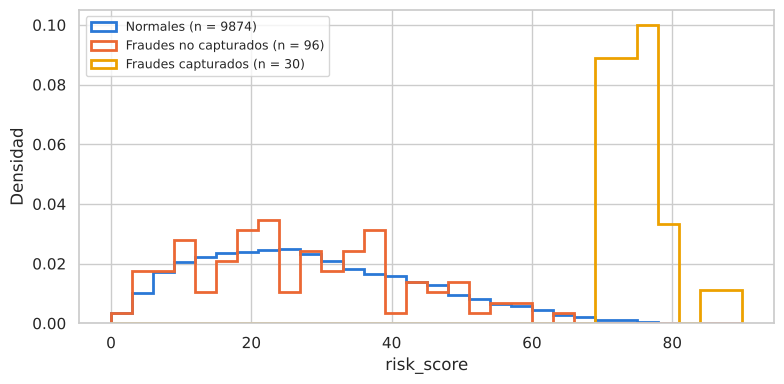

In [15]:
oof = cross_val_predict(pipe(est_brf()), df[FEATS_C], y,
                        cv=StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE), method="predict_proba")[:, 1]
k = int(np.ceil(FRACCION_ALERTAS * len(df)))
top = np.argsort(-oof, kind="stable")[:k]
en_top = np.zeros(len(df), bool)
en_top[top] = True

capturados = df[(y == 1) & en_top]
perdidos = df[(y == 1) & ~en_top]
normales = df[y == 0]
falsos_pos = df[(y == 0) & en_top]
print(f"Alertas revisadas (2 %): {k} → fraudes {int(y[top].sum())} (precisión {y[top].mean():.3f}), falsos positivos {len(falsos_pos)}")
print(f"Fraudes capturados: {len(capturados)} · fraudes no capturados: {len(perdidos)}")
print(f"risk_score mediano → capturados: {capturados['risk_score'].median():.1f} · no capturados: {perdidos['risk_score'].median():.1f} · normales: {normales['risk_score'].median():.1f}")
ks = stats.ks_2samp(perdidos["risk_score"], normales["risk_score"])
print(f"Fraudes no capturados frente a normales (risk_score): KS = {ks.statistic:.3f}, p = {ks.pvalue:.2f}")
print(f"Falsos positivos con risk_score ≥ {UMBRAL}: {int((falsos_pos['risk_score'] >= UMBRAL).sum())} de {len(falsos_pos)}")

fig, ax = plt.subplots(figsize=(8, 4))
bins = np.linspace(0, 90, 31)
for datos, nombre, color in [(normales, "Normales", COLORES[0]), (perdidos, "Fraudes no capturados", COLORES[1]),
                             (capturados, "Fraudes capturados", COLORES[3])]:
    ax.hist(datos["risk_score"], bins=bins, density=True, histtype="step", lw=2, color=color, label=f"{nombre} (n = {len(datos)})")
ax.set_xlabel("risk_score")
ax.set_ylabel("Densidad")
ax.legend(fontsize=9)
savefig("fig_errores")
plt.show()

*Figura (análisis de errores). Distribución de `risk_score` de las transacciones normales, los fraudes que el Random Forest balanceado captura entre el 2 % de mayor puntaje y los que no captura (predicciones fuera de muestra).*

## 8. Conclusiones

Todas las cifras provienen de las 10 particiones externas compartidas con el notebook 03; los intervalos usan la corrección de Nadeau y Bengio y las comparaciones entre estrategias, la prueba t pareada con esa misma corrección. Con 126 fraudes y evaluaciones que comparten datos, la potencia es baja: **que una diferencia no sea significativa no prueba que las estrategias sean equivalentes**, solo que estos datos no permiten distinguirlas.

**1. Techo.** La regla ideal alcanza una PR-AUC de 0,122 (p5–p95: 0,037–0,234) y un recall@2 % de 0,246 en particiones del tamaño de una de prueba. `risk_score` sin modelo obtiene 0,121 [0,045; 0,197] en las particiones reales. Los intervalos de las estrategias de las secciones siguientes se solapan con ese techo: **ninguna estrategia puede, en la práctica, superarlo**. El techo es descriptivo (el umbral 70 salió del análisis exploratorio con todos los datos) y es válido para estas variables, no para variables que no están en el conjunto de datos.

**2. Desbalance (comentarios 1 y 2).**
- *Regresión logística:* la ponderación (PR-AUC 0,065) es **peor** que no tratar el desbalance (0,085; diferencia 0,020; p = 0,019). SMOTENC es el más bajo (0,036; −0,029 respecto a la ponderación; p = 0,060). Una explicación habitual: la ponderación desplaza el umbral de decisión más que el orden de los puntajes, y la PR-AUC solo depende del orden.
- *Gradient boosting:* la ponderación tiene el mayor valor puntual (0,121 frente a 0,102 sin tratamiento y 0,084 con SMOTENC), pero ninguna diferencia es significativa (p = 0,24 y 0,22).
- *Random Forest:* sin tratamiento 0,107, ponderación `balanced_subsample` 0,101, submuestreo por árbol 0,087 y SMOTENC 0,073. El submuestreo por árbol **no mejora** al Random Forest sin tratamiento (p = 0,27); ninguna diferencia es significativa.
- SMOTENC queda por debajo de la estrategia principal en los tres modelos (−0,015 a −0,037), sin significancia estadística (p entre 0,06 y 0,49). Esto respalda la cautela del profesor, pero con estos datos **no permite afirmar** que SMOTE empeore de forma significativa.
- Para el informe: mantener la ponderación y el RF balanceado como estrategias principales por recomendación del profesor, pero reportar con honestidad que **no mejoran de forma significativa la PR-AUC frente a no tratar el desbalance**, y que en la regresión logística la ponderación la empeora.

**3. Indicador de umbral aprendido.** El umbral aprendido en cada partición fue estable (mediana 69,9; rango 69,9–70,6). Añadir `risk_alto` sube la regresión logística de 0,065 a 0,103 (p = 0,094) y la SVM de 0,080 a 0,108 (p = 0,38), llevándolas al nivel de los árboles, y no cambia el gradient boosting (−0,005; p = 0,46). Es coherente con que la señal es un escalón, no una pendiente, aunque la mejora no es estadísticamente significativa.

**4. Paradigmas (comentario 4).**
- Sin `risk_score`, ninguno de los cuatro modelos de una clase supera al azar: PR-AUC entre 0,015 y 0,017 frente a 0,013, y ROC-AUC entre 0,470 y 0,499. **No hay anomalías detectables en las demás variables.**
- Con `risk_score` entre las 23 columnas, se diluyen: PR-AUC de 0,029 a 0,066, frente a 0,121 del gradient boosting supervisado. El clasificador supervisado aprende a ignorar las variables sin señal; los de una clase, no.
- Aplicados a `risk_score` solo, Isolation Forest (0,119), Mahalanobis (0,121) y One-Class SVM con `nu` = 0,05 (0,121) **igualan el techo sin usar etiquetas**; con `nu` = 0,01 el SVM baja a 0,048 y LOF a 0,056–0,092, así que el resultado depende de la configuración. Interpretación: el grupo de fraudes detectables es una cola atípica de la distribución de `risk_score`.
- Justificación del paradigma supervisado para el informe: con las variables completas es claramente superior (0,121 frente a 0,029–0,066), y los enfoques de anomalía solo compiten cuando se les da la única variable informativa.

**5. Puntaje de anomalía como variable (Carcillo et al., 2021).** No aporta: sin `risk_score`, de 0,013 a 0,015 (p = 0,62); con `risk_score`, de 0,114 a 0,112 (p = 0,90).

**6. Historial de `risk_score` (comentario 3).** La media previa (AUC 0,488), el máximo previo (0,487) y el número de transacciones previas con `risk_score` alto (0,496) **no tienen señal**; sus intervalos incluyen 0,5. La diferencia con la media previa (0,606) es `risk_score` disfrazado (su AUC en la misma submuestra es 0,615). Con 126 fraudes el efecto mínimo detectable era una AUC de ≈ 0,573 (≈ 0,580 en la submuestra con historial): un efecto de esa magnitud o mayor se habría visto.

**7. Validación temporal.** Entrenando con el 80 % más antiguo (102 fraudes) y probando con el 20 % más reciente (24 fraudes), los resultados son consistentes con los de la validación cruzada: sin `risk_score`, los tres modelos quedan al nivel del azar (PR-AUC 0,012–0,014; recall@2 % = 0); con `risk_score`, 0,045–0,081 frente a 0,087 de `risk_score` solo. No hay indicio de deriva temporal, aunque la prueba tiene pocos fraudes y los intervalos son amplios (por ejemplo [0,021; 0,250] para `risk_score`).

**8. Errores.** El 2 % de mayor puntaje (200 alertas) captura 30 fraudes (precisión 0,150) y reúne a todas las transacciones con `risk_score` ≥ 70, incluidas 66 falsas alarmas. Los 96 fraudes no capturados tienen un `risk_score` mediano de 25,4 frente a 26,6 de las normales (KS = 0,067; p = 0,76): son indistinguibles de las transacciones normales con estas variables.

**Implicaciones para el informe.**
1. Escribir que los mejores modelos son **equivalentes entre sí y a `risk_score` solo**, y que alcanzan el techo, en lugar de declarar un ganador.
2. Presentar la trazabilidad de los comentarios del profesor con estos resultados, incluidos los desfavorables a la ponderación y al submuestreo.
3. Mantener la limitación de que los hiperparámetros están fijos en este notebook y que las diferencias pequeñas no son concluyentes.
4. Lo que sigue: sección 5 (análisis individual de variables, PCA y UMAP con los dos mejores modelos).